<a href="https://colab.research.google.com/github/vivekvjnk/mathematical_modelling/blob/main/Probability_%26_Statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probability & Statistics
- Probability : Assume distribution is known, samples unknown
- Statistics : Assume samples/data available, distribution unknown (widely used in Machine Learning)
## Index
*What can we do with available data?*

1. Draw a small sample from a huge population
  - Called `survey sampling`
  - How much of sample datapoints are necessary to make useful predictions about the population from sample?
  - Concept of sample mean
    - sample mean ~ normal($μ$, $σ^2/n$)
      - where $μ$ : data set mean
      - $σ$ : variance of data distribution
      - $n$ : sample size
2. Hypothesis testing
  - A/B testing
  - $χ^2$ testing: Are two distributions the same
  - Quantify how significant a result is
  - Experimental design: $P$ value, $P$-hacking
    - How to design a statistical experiment to validate effectiveness of a system
3. Fitting Distributions & Estimating parameters
  - Probability : $P(X | Θ)$
  - Statistis : $P(Θ | X)$
    - method of moments
    - max likelihood estimation(MLE) : Converts parameter estimation to an optimization problem  
    - Goodness of fit & hypothesis testing
    - Confidence intervals on $Θ$; Confidence testing and Hypothesis testing are dual problems
    - Bootstrapping & Monte Carlo simulation
4. Bayesian Statistics
  - Allows to bake in prior knowledge into the modelling
  - Assumes, good prior; Bad prior may lead to bad estimations
5. More
  - Markov chains
  - Random walks
  - etc.


# Sampling a distribution randomly (Survey sampling)

Assumptions:
- There exists a large population of data; $μ$, $σ^2$ are known  
  - $D = {X_1, X_2 ... X_N}$
  - $μ = \frac{1}{N} \sum_{i=1}^{N} X_i$
  - $ \sigma^2 = \frac{1}{N} (\sum_{i=1}^{n} X_i^2 - \mu^2)$

- Sample: small subset from the population set; elements are randomly sampled from the population
  - $s = {x_1, x_2 ... x_n}$
  - $\bar{\mu} = \frac{1}{n} \sum_{i=1}^{n} x_i$
  - $\bar{\sigma}^2 = \frac{1}{n} \sum_{i=1}^{n} x_i^2 - \bar{\mu}^2$

- Assumption : $\binom{N}{n}$ Possible random samples are each equally likely
  - Known as simple random sampling(without replacement)

In [1]:
import numpy as np
import matplotlib.pyplot as plt


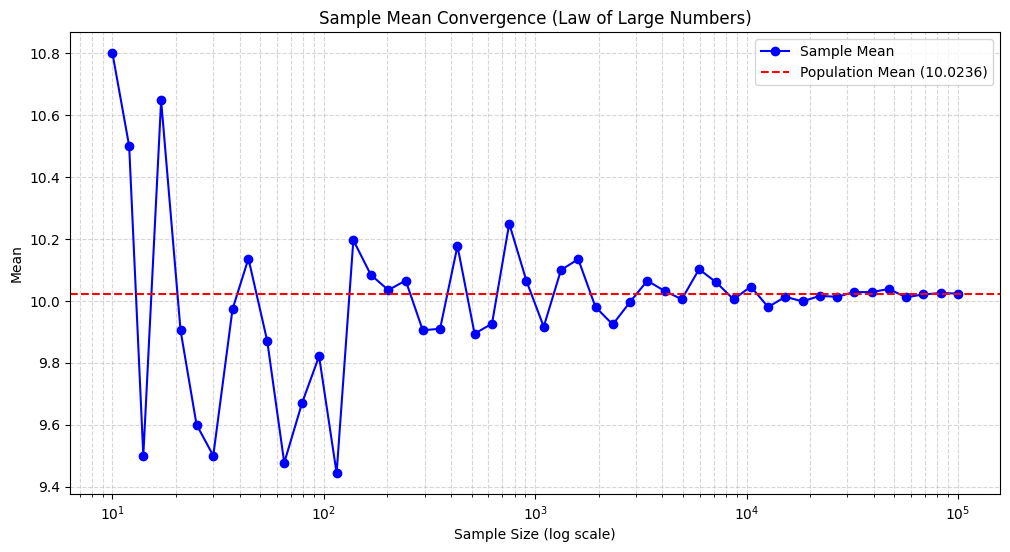

In [13]:
# set random seed
np.random.seed(62)
# Step 1: Generate Poisson distribution of 1000 random samples with specific \lambda
lambda_value = 10
N = 100000
DataPopulation = np.random.poisson(lam=lambda_value, size=N)

# Step 2: Draw random sample from the distribution
n = 10
DataSample = np.random.choice(DataPopulation, size=n, replace=False)

# Step 3: compute mean and standard deviation of both vectors
mean_population = np.mean(DataPopulation)
std_population = np.std(DataPopulation)
mean_sample = np.mean(DataSample)
std_sample = np.std(DataSample)



# Define a range of sample sizes to sweep
sample_sizes = np.logspace(1, 5, num=50, dtype=int)  # sweep from 10 to 10000

sample_means = []

# Perform the sweep
for n_size in sample_sizes:
    # Draw a random sample of size n_size from the population without replacement
    sample = np.random.choice(DataPopulation, size=n_size, replace=False)
    sample_means.append(np.mean(sample))

# Plotting the results
plt.figure(figsize=(12, 6))
plt.plot(sample_sizes, sample_means, marker='o', linestyle='-', color='b', label='Sample Mean')
plt.axhline(y=mean_population, color='r', linestyle='--', label=f'Population Mean ({mean_population:.4f})')

plt.xscale('log')
plt.title('Sample Mean Convergence (Law of Large Numbers)')
plt.xlabel('Sample Size (log scale)')
plt.ylabel('Mean')
plt.legend()
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.show()